# Modeling: Predicting Home Credit Default Risk

Name: Greg Rivera

Date: Oct 19, 2026

## Table of Contents

1. [Introduction](#Introduction)
2. [Setup and configuration](#Setup)
3. [Data preparation](#Data)
    - [3.1 Applying the EDA decisions with `Data_Prep.py`](#3.1)
    - [3.2 Engineered features](#3.2)
    - [3.3 Handling missing values and categorical columns](#3.3)
    - [3.4 Predictor sets](#3.4)
    - [3.5 Pipelines and helper functions](#3.5)
4. [Modeling process](#Modeling)
    - [4.1 Benchmark](#4.1)
    - [4.2 Comparing candidate models](#4.2)
    - [4.3 Class imbalance](#4.3)
    - [4.4 Hyperparameter tuning and final settings](#4.4)
5. [Model performance](#Model)
    - [5.1 Train and holdout performance](#5.1)
    - [5.2 Run time](#5.2)
    - [5.3 Using the score for routing](#5.3)
    - [5.4 What drives the model](#5.4)
6. [Kaggle submission](#Kaggle)
7. [Results](#Results)

# 1. Introduction

**Project goal.** Home Credit lends to people with little or no formal credit history, so standard credit bureau data is often thin or missing for them. The goal of this project is a repayment-risk score for each loan application that helps underwriters decide between automatic approval, automatic decline, and manual review. The Business Problem Statement (BPS) wants lower credit losses and less manual review, and also more approvals for creditworthy thin-file applicants, instead of simply tightening approvals.

**Business problem.** Every decision risks two costly mistakes: approving someone who later has payment difficulty (a credit loss), and declining someone who would have repaid (lost growth and lost access to credit). The score has to be good at telling these two groups apart, it has to be explainable to applicants, and it must not discriminate on protected characteristics.

**Analytic problem.** This is binary classification: predict `TARGET` (1 = payment difficulty) from application data. Only about 8% of applications are positive (8.07% in the training data), so the classes are heavily imbalanced and accuracy is a poor yardstick. A model that predicts "nobody defaults" is 91.9% accurate. I use **AUC** (area under the ROC curve), which measures how well the score *ranks* risky applicants above safe ones, does not depend on a cutoff, and is also the Kaggle metric for this competition. Choosing the cutoffs for approve, decline, and review is a later step.

**Purpose of this notebook.** This notebook takes the cleaned data from my EDA and data-preparation script and builds the score. It (1) sets a benchmark, (2) compares candidate models with cross-validation, (3) tests whether class-imbalance fixes help, (4) tunes the best model, (5) reports how well the final model performs and how long it takes, and (6) creates a Kaggle submission. It ends with what the results mean for the lender.

**Scope note.** I use only the two application tables (`application_train.csv`, `application_test.csv`). I chose not to use the optional supplementary tables (bureau, previous applications, payment histories) in this round. `Data_Prep.py` can build those features, so adding them later is a small change.

# 2. Setup and configuration

All settings that affect speed or reproducibility are in one cell. I use 3-fold cross-validation, one random seed, and the same folds for every model so the comparisons are fair. I compare models using **all** development rows (80% of the training data) and keep the other 20% as an untouched holdout. For tuning I use random subsamples, as the assignment suggests, because a search repeats the fit many times.

In [ ]:
import time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from scipy.stats import loguniform, randint, uniform

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score, roc_curve
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from imblearn.pipeline import Pipeline as ImbPipeline      # resampling is applied inside CV folds only
from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier

import Data_Prep as dp   # data-preparation functions that implement the EDA decisions

warnings.filterwarnings("ignore")        # suppress library warnings so the notebook output stays clean
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 90)

# ---------------- configuration ----------------
SEED = 42                 # one seed everywhere for reproducibility
N_FOLDS = 3               # 3-fold CV for exploration and tuning
N_EXPLORE_ROWS = None     # None = cross-validate on all development rows; an integer uses a stratified subsample
N_TUNE_ROWS = 5_000       # subsample for hyperparameter tuning (assignment setting)
N_TUNE_ROWS_LARGE = 25_000  # second, larger tuning subsample (see section 4.4)
N_ITER = 20               # randomized-search iterations
TOLERANCE = 0.002         # an imbalance fix must beat "no adjustment" by more than this AUC to be used

DATA_DIR = Path("Home Credit Data")
PREPARED_DIR = DATA_DIR / "prepared"
REBUILD_PREPARED = False  # True forces Data_Prep to rebuild instead of re-using the saved CSVs

RUNTIME = {}              # seconds per major step, reported in section 5
np.random.seed(SEED)
cv = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)   # identical folds for every model

# 3. Data preparation


## 3.1 Applying the EDA decisions with `Data_Prep.py`

I do not repeat the cleaning code here. I call the functions in `Data_Prep.py`, which turns each EDA decision into a reusable step. The main transformations are:

| Step | What it does | EDA reason |
|---|---|---|
| Sentinel recoding | `DAYS_EMPLOYED = 365243` becomes missing, plus a flag | 18% of applicants have this placeholder, not a real tenure |
| Days to years | `DAYS_BIRTH`, `DAYS_EMPLOYED` and other negative day counts become positive years | Easier to read and to bin |
| Financial ratios | Credit-to-income, annuity-to-income, income per family member, capped at the 99th percentile | EDA Q2 and Q7 |
| Missing-data indicators | Flags for missing external scores, occupation, enquiry data, and building data | Missingness itself was related to default |
| Bins and interactions | Tenure and age bands, external-score mean/min/max, income type by tenure band | EDA Q1, Q3, Q5 |
| Dropped columns | Building attributes (59-70% missing), near-constant and very rare flags, and the hour/day/week enquiry counts | Too sparse to be useful |
| Rare categories | Levels with fewer than 500 training rows become "Other" | Avoids over-reading tiny groups and handles unseen levels |

**Train and test stay consistent.** Every cap, drop list, and category list is learned from the **training** data only (`fit_preprocessing_params`) and then re-used unchanged on the test data. The check at the end of the next cell confirms that train and test have identical columns (except `TARGET`) and one row per application.

In [ ]:
train_path = PREPARED_DIR / "application_train_prepared.csv"
test_path = PREPARED_DIR / "application_test_prepared.csv"

if train_path.exists() and test_path.exists() and not REBUILD_PREPARED:
    train_df, test_df = pd.read_csv(train_path), pd.read_csv(test_path)
else:
    train_raw = pd.read_csv(DATA_DIR / "application_train.csv")
    test_raw = pd.read_csv(DATA_DIR / "application_test.csv")
    params = dp.fit_preprocessing_params(train_raw)                 # every threshold is learned from TRAIN only
    train_df = dp.prepare_dataset(train_raw, params, is_train=True)
    test_df = dp.prepare_dataset(test_raw, params, is_train=False)  # same params re-used on test
    PREPARED_DIR.mkdir(parents=True, exist_ok=True)
    dp.save_params(params, str(PREPARED_DIR / "params.pkl"))
    dp.save_prepared_datasets(train_df, test_df, str(PREPARED_DIR))

dp.run_integrity_checks(train_df, test_df)    # identical columns (except TARGET) and one row per SK_ID_CURR
print(f"train {train_df.shape} | test {test_df.shape} | default rate {train_df['TARGET'].mean():.4f}")

  Train and test share 83 columns (TARGET excluded): OK
  train: 307511 rows, 307511 unique SK_ID_CURR -- one row per application: OK
  test: 48744 rows, 48744 unique SK_ID_CURR -- one row per application: OK
train (307511, 84) | test (48744, 83) | default rate 0.0807


## 3.2 Engineered features

The table below lists the new features that `Data_Prep.py` added, grouped by type. Altogether it creates 24 new columns from the original application fields.

In [ ]:
ID_COL, TARGET_COL = "SK_ID_CURR", "TARGET"
feature_cols_all = [c for c in train_df.columns if c not in (ID_COL, TARGET_COL)]

families = {
    "Days converted to years": ["AGE_YEARS", "EMPLOYMENT_YEARS", "REGISTRATION_YEARS", "ID_PUBLISH_YEARS", "LAST_PHONE_CHANGE_YEARS"],
    "Financial ratios": ["CREDIT_INCOME_RATIO", "ANNUITY_INCOME_RATIO", "INCOME_PER_FAMILY_MEMBER"],
    "Missing-data indicators": [c for c in feature_cols_all if c.endswith("_MISSING")] +
                               ["DAYS_EMPLOYED_SENTINEL_FLAG", "NO_ENQUIRY_DATA", "HAS_BUILDING_INFO"],
    "Bins, aggregates, interactions": ["EMPLOYMENT_YEARS_BAND", "AGE_BAND", "EXT_SOURCE_MEAN", "EXT_SOURCE_MIN",
                                       "EXT_SOURCE_MAX", "EXT_SOURCE_COUNT_AVAILABLE", "ENQUIRY_COUNT_TOTAL",
                                       "INCOME_TYPE_X_EMPLOYMENT_BAND"],
}
rows = []
for fam, cols in families.items():
    present = [c for c in cols if c in feature_cols_all]
    rows.append({"Feature family": fam, "Columns": len(present), "Names": ", ".join(present)})
display(pd.DataFrame(rows))

,Feature family,Columns,Names
0,Days converted to years,5,"AGE_YEARS, EMPLOYMENT_YEARS, REGISTRATION_YEARS, ID_PUBLISH_YEARS, LAST_PHONE_CHANGE_Y..."
1,Financial ratios,3,"CREDIT_INCOME_RATIO, ANNUITY_INCOME_RATIO, INCOME_PER_FAMILY_MEMBER"
2,Missing-data indicators,8,"EXT_SOURCE_1_MISSING, EXT_SOURCE_2_MISSING, EXT_SOURCE_3_MISSING, OCCUPATION_TYPE_MISS..."
3,"Bins, aggregates, interactions",8,"EMPLOYMENT_YEARS_BAND, AGE_BAND, EXT_SOURCE_MEAN, EXT_SOURCE_MIN, EXT_SOURCE_MAX, EXT_..."


## 3.3 Handling missing values and categorical columns

I treat missing values in three ways:

- **Missing is informative, so I flag it.** The indicator columns above tell the model that a value was missing. This matters most for the external scores: `EXT_SOURCE_1` is missing for 56.4% of applicants and `EXT_SOURCE_3` for 19.8%. I do not fill these with a single number in the preparation step.
- **Remaining numeric gaps are filled inside the model pipeline.** Each pipeline uses a median imputer that is fit on the training part of each cross-validation fold only, so no information leaks from the validation fold.
- **Categorical gaps get their own level.** Text columns get an explicit `"Missing"` category, and the one-hot encoder groups very rare levels together.

After this step the data has 82 candidate features (69 numeric and 13 categorical). 22 numeric columns still contain missing values. The cell below shows the largest shares. The three enquiry columns are missing together (13.5%), and `DAYS_EMPLOYED` is missing for the 18.0% of applicants with the sentinel.

Finally, I hold out a random 20% of the training data (`X_hold`). It is not used for comparing models or for tuning, only for the final checks.

In [ ]:
# Non-numeric columns are categorical (this includes the binned tenure and age columns).
cat_cols_all = [c for c in feature_cols_all if not pd.api.types.is_numeric_dtype(train_df[c])]
for df in (train_df, test_df):
    for c in cat_cols_all:
        df[c] = df[c].astype(object).where(df[c].notna(), "Missing")    # explicit level for missing categories

X_train, y_train = train_df[feature_cols_all], train_df[TARGET_COL].astype(int)
X_test = test_df[feature_cols_all]

# Hold out 20% of train up front. It is not used for model comparison or tuning, only for the final checks.
X_dev, X_hold, y_dev, y_hold = train_test_split(X_train, y_train, test_size=0.2, stratify=y_train, random_state=SEED)
POS_WEIGHT = (y_train == 0).sum() / (y_train == 1).sum()      # used only by XGBoost's class-weight option

num_cols_all = [c for c in feature_cols_all if c not in cat_cols_all]
na_share = X_train[num_cols_all].isna().mean().sort_values(ascending=False)
print(f"{len(feature_cols_all)} candidate features: {len(num_cols_all)} numeric, {len(cat_cols_all)} categorical")
print(f"{int((na_share > 0).sum())} numeric columns still contain missing values; the largest shares are:")
display(na_share[na_share > 0].head(8).rename("share missing").to_frame().round(3))

82 candidate features: 69 numeric, 13 categorical
22 numeric columns still contain missing values; the largest shares are:


,share missing
EXT_SOURCE_1,0.564
EXT_SOURCE_3,0.198
DAYS_EMPLOYED,0.180
EMPLOYMENT_YEARS,0.180
AMT_REQ_CREDIT_BUREAU_YEAR,0.135
AMT_REQ_CREDIT_BUREAU_QRT,0.135
AMT_REQ_CREDIT_BUREAU_MON,0.135
DEF_30_CNT_SOCIAL_CIRCLE,0.003


## 3.4 Predictor sets

The EDA (Q9) separated the features into a transparent baseline set and a group of **high-governance** fields (education, family status, housing, occupation, organization, region, gender, and age). Those fields showed real differences, but they can act as proxies for disadvantage or protected traits. To measure what they add, I compare three predictor sets:

- **Baseline (EDA Q9):** affordability ratios, external scores with missing flags, employment stability, and credit enquiries.
- **All minus governed:** every feature except the high-governance fields (and fields derived from them).
- **All features:** everything, including the high-governance fields.

In [ ]:
baseline_wanted = [
    "NAME_CONTRACT_TYPE", "AMT_INCOME_TOTAL", "AMT_CREDIT", "AMT_ANNUITY", "AMT_GOODS_PRICE",      # affordability
    "CREDIT_INCOME_RATIO", "ANNUITY_INCOME_RATIO", "INCOME_PER_FAMILY_MEMBER",
    "EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3",                                               # external scores
    "EXT_SOURCE_1_MISSING", "EXT_SOURCE_2_MISSING", "EXT_SOURCE_3_MISSING",
    "EXT_SOURCE_MEAN", "EXT_SOURCE_MIN", "EXT_SOURCE_MAX", "EXT_SOURCE_COUNT_AVAILABLE",
    "NAME_INCOME_TYPE", "EMPLOYMENT_YEARS", "EMPLOYMENT_YEARS_BAND",                              # employment stability
    "DAYS_EMPLOYED_SENTINEL_FLAG", "INCOME_TYPE_X_EMPLOYMENT_BAND",
    "AMT_REQ_CREDIT_BUREAU_MON", "AMT_REQ_CREDIT_BUREAU_QRT", "AMT_REQ_CREDIT_BUREAU_YEAR",      # credit seeking
    "ENQUIRY_COUNT_TOTAL", "NO_ENQUIRY_DATA",
]
baseline_cols = [c for c in baseline_wanted if c in feature_cols_all]

# High-governance fields from the EDA, plus fields derived from the same families.
governed = set(dp.HIGH_GOVERNANCE_FEATURES) | {
    "DAYS_BIRTH", "AGE_BAND", "OCCUPATION_TYPE_MISSING", "CNT_CHILDREN",
    "REG_REGION_NOT_LIVE_REGION", "REG_REGION_NOT_WORK_REGION", "LIVE_REGION_NOT_WORK_REGION",
    "REG_CITY_NOT_LIVE_CITY", "REG_CITY_NOT_WORK_CITY", "LIVE_CITY_NOT_WORK_CITY",
}
nogov_cols = [c for c in feature_cols_all if c not in governed]

predictor_sets = {"Baseline (EDA Q9)": baseline_cols,
                  "All minus governed": nogov_cols,
                  "All features": feature_cols_all}
display(pd.DataFrame({"Predictor set": list(predictor_sets), "Features": [len(v) for v in predictor_sets.values()]}))

,Predictor set,Features
0,Baseline (EDA Q9),28
1,All minus governed,62
2,All features,82


## 3.5 Pipelines and helper functions

Every model is wrapped in a scikit-learn **pipeline** with the same preprocessing: median imputation and one-hot encoding, plus scaling for logistic regression only (it is sensitive to feature scale). Because the preprocessing lives inside the pipeline, cross-validation re-fits it on each training fold and never sees the validation fold. The pipeline builder also takes a class-imbalance strategy, which lets me switch it in one argument in section 4.3. Resampling uses the `imblearn` pipeline, so it only touches the training part of each fold and the validation folds keep the real 8% default rate.

In [ ]:
def make_preprocessor(cols, scale=False):
    num = [c for c in cols if c not in cat_cols_all]
    cat = [c for c in cols if c in cat_cols_all]
    num_steps = [("impute", SimpleImputer(strategy="median"))]
    if scale:
        num_steps.append(("scale", StandardScaler()))
    parts = [("num", Pipeline(num_steps), num)]
    if cat:
        parts.append(("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=30,
                                           sparse_output=False, dtype=np.float32), cat))
    return ColumnTransformer(parts)


def make_model(key, class_weight=False):
    # class_weight is the built-in imbalance fix; each library names it differently.
    if key == "logreg":
        return LogisticRegression(max_iter=2000, C=1.0, class_weight="balanced" if class_weight else None)
    if key == "rf":
        return RandomForestClassifier(n_estimators=300, min_samples_leaf=20, max_features="sqrt", n_jobs=-1,
                                      random_state=SEED, class_weight="balanced_subsample" if class_weight else None)
    if key == "lgbm":
        return LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31, subsample=0.8, subsample_freq=1,
                              colsample_bytree=0.8, random_state=SEED, n_jobs=-1, verbose=-1,
                              class_weight="balanced" if class_weight else None)
    if key == "xgb":
        return XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4, subsample=0.8, colsample_bytree=0.8,
                             tree_method="hist", eval_metric="auc", random_state=SEED, n_jobs=-1,
                             scale_pos_weight=POS_WEIGHT if class_weight else 1.0)
    raise ValueError(key)


def make_pipeline(model_key, cols, strategy="none"):
    # strategy: none | class_weight | undersample | oversample | smote
    pre = make_preprocessor(cols, scale=(model_key == "logreg"))
    model = make_model(model_key, class_weight=(strategy == "class_weight"))
    sampler = {"undersample": RandomUnderSampler(random_state=SEED),
               "oversample": RandomOverSampler(random_state=SEED),
               "smote": SMOTE(random_state=SEED)}.get(strategy)
    if sampler is None:
        return Pipeline([("pre", pre), ("model", model)])
    return ImbPipeline([("pre", pre), ("sampler", sampler), ("model", model)])   # sampler only touches training folds


def cv_score(pipe, X, y, label):
    # Cross-validated AUC (main metric) and accuracy (to show why accuracy misleads).
    t0 = time.time()
    res = cross_validate(pipe, X, y, cv=cv, scoring={"auc": "roc_auc", "acc": "accuracy"}, error_score="raise")
    return {"model": label, "cv_auc": res["test_auc"].mean(), "auc_std": res["test_auc"].std(),
            "cv_accuracy": res["test_acc"].mean(), "seconds": round(time.time() - t0, 1)}


# Stratified exploration subsample shared by every model, so the comparison is like for like.
if N_EXPLORE_ROWS and N_EXPLORE_ROWS < len(X_dev):
    idx, _ = train_test_split(np.arange(len(X_dev)), train_size=N_EXPLORE_ROWS, stratify=y_dev, random_state=SEED)
else:
    idx = np.arange(len(X_dev))
X_exp, y_exp = X_dev.iloc[idx].reset_index(drop=True), y_dev.iloc[idx].reset_index(drop=True)
print(f"Rows used for model comparison: {len(X_exp):,} (default rate {y_exp.mean():.4f}); holdout: {len(X_hold):,}")

Rows used for model comparison: 246,008 (default rate 0.0807); holdout: 61,503


# 4. Modeling process

I follow four steps. Each is scored with the same 3-fold stratified cross-validation (every fold keeps the 8% default rate) on the same development rows, and the main metric is AUC.

| Step | What I do | How I choose |
|---|---|---|
| 4.1 Benchmark | Majority-class classifier and a one-variable logistic regression | Sets the numbers to beat |
| 4.2 Candidates | Logistic regression on three predictor sets, random forest, LightGBM, XGBoost, and the boosted models without the governed fields (8 models) | Highest cross-validated AUC |
| 4.3 Class imbalance | Compare no adjustment, class weights, down-sampling, up-sampling, and SMOTE | Keep "none" unless something wins by more than 0.002 AUC |
| 4.4 Tuning | Randomized search (20 settings) with 3-fold CV on 5,000-row and 25,000-row subsamples; then a holdout check | Best AUC on the untouched holdout |

After the best model is chosen, I train it on **all** training data and report its performance in section 5.

## 4.1 Benchmark

I need numbers to beat before building anything complicated. I use two benchmarks:

1. **Majority-class classifier:** always predicts "no payment difficulty". It shows what happens when a model learns nothing.
2. **A simple model:** logistic regression on one feature, `EXT_SOURCE_MEAN` (the mean of the external scores). The EDA (Q1) found the external scores were the strongest single signal, so this is a simple scorecard that a complex model has to beat.

In [ ]:
bench_df = pd.DataFrame([
    cv_score(DummyClassifier(strategy="most_frequent"), X_exp[["EXT_SOURCE_MEAN"]], y_exp, "Majority class"),
    cv_score(make_pipeline("logreg", ["EXT_SOURCE_MEAN"]), X_exp, y_exp, "Logistic regression on EXT_SOURCE_MEAN"),
])
display(bench_df.round(4))
BASE_ACC, BASE_AUC = bench_df.loc[0, "cv_accuracy"], bench_df.loc[0, "cv_auc"]
SIMPLE_AUC = bench_df.loc[1, "cv_auc"]

,model,cv_auc,auc_std,cv_accuracy,seconds
0,Majority class,0.5000,0.0000,0.9193,0.1
1,Logistic regression on EXT_SOURCE_MEAN,0.7164,0.0017,0.9193,0.9


**Reading the benchmark.** The majority classifier has accuracy 0.9193 (just the share of non-defaulters) and AUC exactly 0.5, because it gives every applicant the same score and cannot rank anyone. That AUC is the floor. The one-variable model keeps the same accuracy but reaches **AUC 0.716**, so a single explainable number already ranks applicants far better than chance. For the lender, this is the bar for the rest of the notebook: a complex model only earns its extra complexity if it clearly beats 0.716. It also shows that accuracy hides the difference (both models have the same accuracy), which is why I compare models on AUC.

## 4.2 Comparing candidate models

I compare eight models on cross-validated AUC:

- **Logistic regression** on the three predictor sets. It is the easiest to explain, and it shows what each block of information adds.
- **Random forest, LightGBM, and XGBoost** on all features. Tree models can find non-linear effects and interactions without me specifying them.
- **LightGBM and XGBoost without the governed fields**, so I can measure what those fields add for a strong model.

I show accuracy next to AUC to make the point that accuracy cannot separate the models.

In [ ]:
candidates = {}
for set_name, cols in predictor_sets.items():
    candidates[f"LogReg | {set_name}"] = ("logreg", cols)
candidates["Random forest | All features"] = ("rf", feature_cols_all)
candidates["LightGBM | All features"] = ("lgbm", feature_cols_all)
candidates["LightGBM | All minus governed"] = ("lgbm", nogov_cols)
candidates["XGBoost | All features"] = ("xgb", feature_cols_all)
candidates["XGBoost | All minus governed"] = ("xgb", nogov_cols)

compare_df = pd.DataFrame([cv_score(make_pipeline(k, cols), X_exp, y_exp, name)
                           for name, (k, cols) in candidates.items()])
compare_df = compare_df.sort_values("cv_auc", ascending=False).reset_index(drop=True)
RUNTIME["Model comparison (8 models x 3 folds)"] = compare_df["seconds"].sum()
display(compare_df.round(4))

,model,cv_auc,auc_std,cv_accuracy,seconds
0,XGBoost | All features,0.7568,0.0007,0.9196,46.9
1,LightGBM | All features,0.7552,0.0008,0.9195,38.9
2,LogReg | All features,0.7500,0.0012,0.9194,16.6
3,XGBoost | All minus governed,0.7489,0.0007,0.9195,28.5
4,LightGBM | All minus governed,0.7471,0.0009,0.9194,31.2
5,Random forest | All features,0.7454,0.0012,0.9193,379.0
6,LogReg | All minus governed,0.7416,0.0010,0.9194,7.5
7,LogReg | Baseline (EDA Q9),0.7375,0.0010,0.9193,4.7


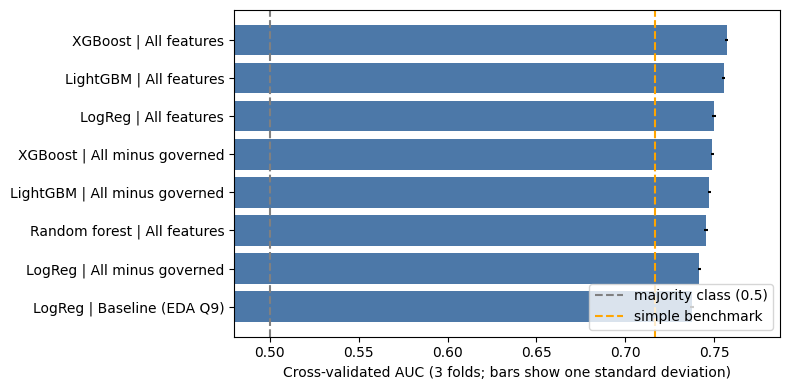

,With governed fields,Without governed fields,Lift from governed fields
Logistic regression,0.7500,0.7416,0.0084
LightGBM,0.7552,0.7471,0.0081
XGBoost,0.7568,0.7489,0.0079


Carried forward: XGBoost | All features


In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))
plot_df = compare_df.iloc[::-1]
ax.barh(plot_df["model"], plot_df["cv_auc"], xerr=plot_df["auc_std"], color="#4C78A8")
ax.axvline(0.5, color="gray", ls="--", label="majority class (0.5)")
ax.axvline(SIMPLE_AUC, color="orange", ls="--", label="simple benchmark")
ax.set_xlim(0.48, plot_df["cv_auc"].max() + 0.03)
ax.set_xlabel("Cross-validated AUC (3 folds; bars show one standard deviation)")
ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

auc = compare_df.set_index("model")["cv_auc"]
lift_table = pd.DataFrame({
    "With governed fields": [auc["LogReg | All features"], auc["LightGBM | All features"], auc["XGBoost | All features"]],
    "Without governed fields": [auc["LogReg | All minus governed"], auc["LightGBM | All minus governed"],
                                auc["XGBoost | All minus governed"]],
}, index=["Logistic regression", "LightGBM", "XGBoost"])
lift_table["Lift from governed fields"] = lift_table.iloc[:, 0] - lift_table.iloc[:, 1]
display(lift_table.round(4))

CARRY_FORWARD_OVERRIDE = None          # set to a model name from the table to force a different choice
best_name = CARRY_FORWARD_OVERRIDE or compare_df.loc[0, "model"]
best_key, best_cols = candidates[best_name]
best_row = compare_df[compare_df["model"] == best_name].iloc[0]
print(f"Carried forward: {best_name}")

**Reading the comparison.** Accuracy is about 0.919 for every model, so it tells me nothing. AUC separates them, and the fold-to-fold standard deviation is only about 0.001, so even small gaps are real here.

- **XGBoost on all features wins (AUC 0.7568)**, with LightGBM close behind (0.7552). Both beat logistic regression on all features (0.7500) by about 0.005-0.007 AUC, so there are non-linear effects that boosting captures. The random forest is lower (0.7454) and by far the slowest (about 6 minutes for the three folds, against 17 seconds for logistic regression).
- **Predictor sets:** with logistic regression, AUC rises from 0.7375 (EDA baseline) to 0.7416 (all minus governed) to 0.7500 (all features). The EDA baseline is already close to the others, so the explainable feature set carries most of the signal.
- **High-governance fields add about 0.008 AUC** for all three model types (table above). A strong model without them (XGBoost, 0.7489) is about as good as logistic regression with them (0.7500). For the lender, this is the price of leaving out fields that could proxy for protected traits, and it is small.

I carry the top model, XGBoost on all features, into the next steps. Note that the best model uses gender and age-related fields, which the EDA said should not be used in a production score; I come back to this in sections 5.4 and 7.

## 4.3 Class imbalance

Because only about 8% of applicants have payment difficulty, a model can lower its training error by mostly predicting the majority class. I test the common fixes:

| Strategy | What it does | Main risk |
|---|---|---|
| None | Train on the data as it is | May focus on the majority class |
| Class weights | Penalize mistakes on the rare class more | Inflates predicted probabilities |
| Down-sampling | Drop majority rows until classes are balanced | Throws away most of the data |
| Up-sampling | Repeat minority rows until balanced | Can over-fit repeated rows |
| SMOTE | Create synthetic minority rows between neighbors | Synthetic applicants are not real; one-hot columns become fractions |

I test them on the carried-forward model (XGBoost) and on logistic regression for contrast. Resampling happens inside each training fold only.

In [ ]:
strategies = ["none", "class_weight", "undersample", "oversample", "smote"]
model_labels = {"logreg": "Logistic regression", "rf": "Random forest", "lgbm": "LightGBM", "xgb": "XGBoost"}
imb_models = {best_key: best_cols}
imb_models.setdefault("logreg", best_cols)       # logistic regression as a contrast model

imb_rows = []
for key, cols in imb_models.items():
    for strat in strategies:
        r = cv_score(make_pipeline(key, cols, strat), X_exp, y_exp, strat)
        r.update({"model_type": model_labels[key], "strategy": strat})
        imb_rows.append(r)
imb_df = pd.DataFrame(imb_rows)
RUNTIME["Imbalance experiment (2 models x 5 strategies x 3 folds)"] = imb_df["seconds"].sum()

auc_tab = imb_df.pivot(index="strategy", columns="model_type", values="cv_auc").loc[strategies]
acc_tab = imb_df.pivot(index="strategy", columns="model_type", values="cv_accuracy").loc[strategies]
display(pd.concat({"CV AUC": auc_tab, "CV accuracy": acc_tab}, axis=1).round(4))

CV AUC                 CV accuracy        
model_type   Logistic regression XGBoost Logistic regression XGBoost
strategy                                                            
none                      0.7500  0.7568              0.9194  0.9196
class_weight              0.7498  0.7562              0.6866  0.7066
undersample               0.7484  0.7543              0.6836  0.6929
oversample                0.7496  0.7557              0.6866  0.7074
smote                     0.7422  0.7512              0.6954  0.9194

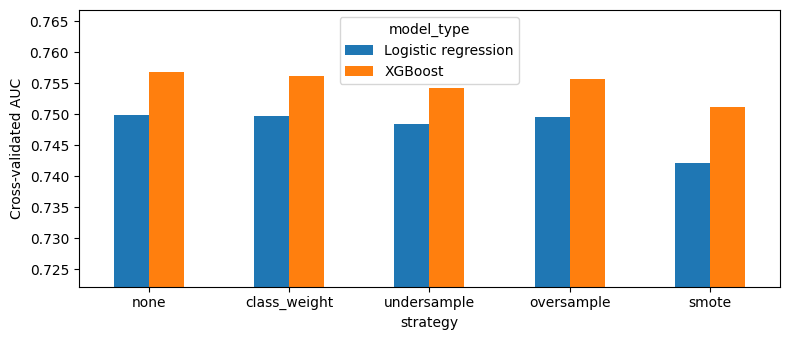

XGBoost: best alternative 'none' changes AUC by +0.0000; strategy used for tuning: 'none'


In [ ]:
fig, ax = plt.subplots(figsize=(8, 3.5))
auc_tab.plot(kind="bar", ax=ax, rot=0)
ax.set_ylim(max(0.5, auc_tab.min().min() - 0.02), auc_tab.max().max() + 0.01)
ax.set_ylabel("Cross-validated AUC")
plt.tight_layout(); plt.show()

# Keep "none" unless another strategy beats it by more than TOLERANCE for the carried-forward model.
best_rows = imb_df[imb_df["model_type"] == model_labels[best_key]].set_index("strategy")
no_adjust = best_rows.loc["none", "cv_auc"]
top_strategy = best_rows["cv_auc"].idxmax()
best_strategy = top_strategy if best_rows.loc[top_strategy, "cv_auc"] - no_adjust > TOLERANCE else "none"
print(f"{model_labels[best_key]}: best alternative '{top_strategy}' changes AUC by "
      f"{best_rows.loc[top_strategy, 'cv_auc'] - no_adjust:+.4f}; strategy used for tuning: '{best_strategy}'")

**Reading the imbalance results.** For both models, **no adjustment gives the best AUC** (XGBoost 0.7568, logistic regression 0.7500). Class weights come very close (0.7562 and 0.7498) and the other strategies are lower, with down-sampling and SMOTE losing the most (XGBoost 0.7543 and 0.7512). So fixing the imbalance did not help the ranking, and the selection rule keeps "none".

Accuracy at the default 0.5 cutoff falls from about 0.92 to 0.68-0.71 for class weights and up-/down-sampling. This is a cutoff effect, not a worse model: the model is now pushed to flag many more applicants as risky. (SMOTE with XGBoost leaves accuracy at 0.9194, meaning it still rarely predicts the minority class at 0.5.)

**Why this happens, and what it means for the lender.** AUC depends only on how applicants are *ranked*, and resampling mostly changes how confident the model is, not the order. The adjustments also inflate predicted probabilities, so a predicted 0.4 would no longer mean about a 40% chance of default, which would break any expected-loss calculation. Down-sampling discards most of the rows, and SMOTE creates applicants who never existed, which is hard to defend to a regulator. So I train on the real default rate and will pick cutoffs from costs later.

## 4.4 Hyperparameter tuning and final settings

I tune XGBoost with **randomized search**: 20 random combinations of hyperparameters (learning rate, tree depth, number of trees, regularization, sampling rates), drawn from ranges I set, with 3-fold CV. A full grid search would take far too long. I follow the assignment's speed-up, so the first search uses only a **5,000-row stratified subsample** (about 400 defaults), and the final model is then trained on all training rows.

I show the five best settings, plus the default settings scored on the same 5,000 rows so I can see what tuning bought.

In [ ]:
# Search ranges per model family; parameter names follow the pipeline step name ('model__<parameter>').
param_distributions = {
    "lgbm": {"model__n_estimators": randint(100, 600), "model__learning_rate": loguniform(0.01, 0.2),
             "model__num_leaves": randint(8, 64), "model__min_child_samples": randint(20, 200),
             "model__subsample": uniform(0.6, 0.4), "model__colsample_bytree": uniform(0.5, 0.5),
             "model__reg_alpha": loguniform(1e-3, 10), "model__reg_lambda": loguniform(1e-3, 10)},
    "xgb": {"model__n_estimators": randint(100, 600), "model__learning_rate": loguniform(0.01, 0.2),
            "model__max_depth": randint(2, 8), "model__min_child_weight": randint(1, 20),
            "model__subsample": uniform(0.6, 0.4), "model__colsample_bytree": uniform(0.5, 0.5),
            "model__reg_alpha": loguniform(1e-3, 10), "model__reg_lambda": loguniform(1e-3, 10)},
    "rf": {"model__n_estimators": randint(200, 500), "model__max_depth": [6, 10, 14, None],
           "model__min_samples_leaf": randint(5, 100), "model__max_features": ["sqrt", 0.2, 0.4]},
    "logreg": {"model__C": loguniform(1e-3, 10)},
}

def run_search(n_rows):
    # Randomized search with 3-fold CV on a stratified subsample of the development data.
    X_s, _, y_s, _ = train_test_split(X_dev, y_dev, train_size=n_rows, stratify=y_dev, random_state=SEED)
    srch = RandomizedSearchCV(make_pipeline(best_key, best_cols, best_strategy), param_distributions[best_key],
                              n_iter=N_ITER, scoring="roc_auc", cv=cv, random_state=SEED, n_jobs=1, refit=True)
    t0 = time.time()
    srch.fit(X_s, y_s)
    secs = time.time() - t0
    base = cross_validate(make_pipeline(best_key, best_cols, best_strategy), X_s, y_s,
                          cv=cv, scoring="roc_auc")["test_score"].mean()
    return srch, base, secs


def top_settings(srch, n=5):
    res = pd.DataFrame(srch.cv_results_).sort_values("rank_test_score")
    keep = ["mean_test_score", "std_test_score"] + [c for c in res.columns if c.startswith("param_")]
    return res[keep].head(n).rename(columns=lambda c: c.replace("param_model__", "")).round(4)


search_small, base_small, secs_small = run_search(N_TUNE_ROWS)
RUNTIME[f"Randomized search ({N_ITER} settings x 3 folds, {N_TUNE_ROWS:,} rows)"] = secs_small
display(top_settings(search_small))
print(f"Default settings on the same {N_TUNE_ROWS:,} rows: {base_small:.4f} | best of {N_ITER} random settings: "
      f"{search_small.best_score_:.4f} ({search_small.best_score_ - base_small:+.4f})")

,mean_test_score,std_test_score,colsample_bytree,learning_rate,max_depth,min_child_weight,n_estimators,reg_alpha,reg_lambda,subsample
19,0.7106,0.0259,0.9715,0.0263,2,17,417,7.7113,7.0760,0.7007
14,0.7095,0.0212,0.7197,0.0183,2,4,321,0.0036,0.2616,0.8159
5,0.7089,0.0286,0.6927,0.0105,3,15,543,0.0031,0.0957,0.6138
17,0.7081,0.0263,0.9480,0.0259,2,1,476,0.3897,0.0010,0.7410
10,0.7052,0.0235,0.5994,0.0102,4,19,180,0.7004,1.4478,0.8424


Default settings on the same 5,000 rows: 0.6824 | best of 20 random settings: 0.7106 (+0.0282)


**Reading the first search.** On the 5,000 rows, the best random setting scores 0.7106 against 0.6824 for the default settings, so tuning appears to help by 0.028. But the fold-to-fold standard deviation is about 0.026, as big as the gain, and I picked the best of 20 on the same folds, so part of the gain is selection luck. Most of the top settings use very shallow trees (depth 2-3) and strong regularization. That is what suits a small sample, where a flexible model overfits quickly. I should not assume it carries over to 246,000 rows.

Because of that concern, I run the same search again on a larger **25,000-row** subsample, which is a middle ground between the 5,000-row subsample and the full data.

In [ ]:
search_large, base_large, secs_large = run_search(N_TUNE_ROWS_LARGE)
RUNTIME[f"Randomized search ({N_ITER} settings x 3 folds, {N_TUNE_ROWS_LARGE:,} rows)"] = secs_large
display(top_settings(search_large, 3))
print(f"Default settings on the same {N_TUNE_ROWS_LARGE:,} rows: {base_large:.4f} | best of {N_ITER} random settings: "
      f"{search_large.best_score_:.4f} ({search_large.best_score_ - base_large:+.4f})")

,mean_test_score,std_test_score,colsample_bytree,learning_rate,max_depth,min_child_weight,n_estimators,reg_alpha,reg_lambda,subsample
9,0.7420,0.0058,0.6405,0.0508,2,15,400,0.0020,8.8623,0.9089
19,0.7414,0.0049,0.9715,0.0263,2,17,417,7.7113,7.0760,0.7007
18,0.7413,0.0061,0.6524,0.0164,4,9,417,0.0077,0.0030,0.7350


Default settings on the same 25,000 rows: 0.7352 | best of 20 random settings: 0.7420 (+0.0068)


**Which settings should the final model use?** Cross-validation on a subsample is only a proxy for the full-data model. So I fit three versions of XGBoost on the full development data (default settings, the 5,000-row winner, and the 25,000-row winner) and score each on the 20% holdout that has not been used for any decision so far. The settings with the best holdout AUC are used for the final model.

In [ ]:
# Fit each set of settings on the development data and score the untouched holdout.
settings = {"Default settings": make_pipeline(best_key, best_cols, best_strategy),
            f"Tuned on {N_TUNE_ROWS:,} rows": clone(search_small.best_estimator_),
            f"Tuned on {N_TUNE_ROWS_LARGE:,} rows": clone(search_large.best_estimator_)}
fitted, rows = {}, []
for name, pipe in settings.items():
    t0 = time.time()
    fitted[name] = pipe.fit(X_dev, y_dev)
    fit_secs = time.time() - t0
    rows.append({"Settings": name, "Holdout AUC": roc_auc_score(y_hold, fitted[name].predict_proba(X_hold)[:, 1]),
                 "Fit seconds": round(fit_secs, 1)})
check_df = pd.DataFrame(rows)
display(check_df.round(4))

final_name = check_df.loc[check_df["Holdout AUC"].idxmax(), "Settings"]    # settings used for the final model
chosen_pipe = clone(settings[final_name])
print(f"Settings used for the final model: {final_name}")

,Settings,Holdout AUC,Fit seconds
0,Default settings,0.7596,20.6
1,"Tuned on 5,000 rows",0.7495,23.0
2,"Tuned on 25,000 rows",0.7544,21.0


Settings used for the final model: Default settings


# 5. Model performance

## 5.1 Train and holdout performance

The holdout check above chose the final settings. This cell reports how that model performs on the data it was trained on versus the holdout it has never seen. The gap between the two shows how much the model overfits. The ROC curve shows the holdout tradeoff between catching defaults (true positives) and flagging safe applicants (false positives).

The real test set (`application_test.csv`) has no labels, so I cannot score it myself. Its performance is measured by the Kaggle score in section 6, and the holdout is my stand-in for it.

,Data,AUC,Accuracy
0,"Train (80%, used to fit)",0.7783,0.9201
1,"Holdout (20%, never used for fitting or tuning)",0.7596,0.9197
2,Majority class (benchmark),0.5000,0.9193


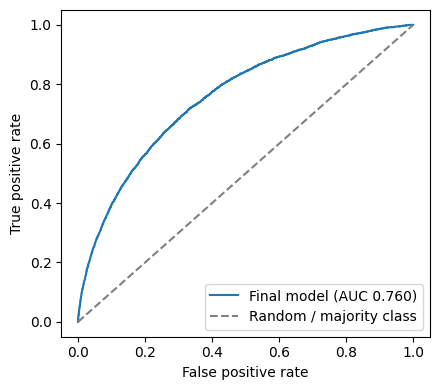

In [ ]:
val_pipe = fitted[final_name]                       # fitted on the development data (80% of train)
y_va = y_hold
t0 = time.time()
p_va = val_pipe.predict_proba(X_hold)[:, 1]
RUNTIME[f"Holdout model: score {len(X_hold):,} applications"] = time.time() - t0
p_tr = val_pipe.predict_proba(X_dev)[:, 1]
RUNTIME["Holdout model: fit on 80% of train"] = check_df.loc[check_df["Settings"] == final_name, "Fit seconds"].iloc[0]

HOLDOUT_AUC, HOLDOUT_ACC = roc_auc_score(y_hold, p_va), accuracy_score(y_hold, p_va >= 0.5)
TRAIN80_AUC, TRAIN80_ACC = roc_auc_score(y_dev, p_tr), accuracy_score(y_dev, p_tr >= 0.5)
display(pd.DataFrame({"Data": ["Train (80%, used to fit)", "Holdout (20%, never used for fitting or tuning)",
                               "Majority class (benchmark)"],
                      "AUC": [TRAIN80_AUC, HOLDOUT_AUC, BASE_AUC],
                      "Accuracy": [TRAIN80_ACC, HOLDOUT_ACC, 1 - y_hold.mean()]}).round(4))

fpr, tpr, _ = roc_curve(y_hold, p_va)
fig, ax = plt.subplots(figsize=(4.5, 4))
ax.plot(fpr, tpr, label=f"Final model (AUC {HOLDOUT_AUC:.3f})")
ax.plot([0, 1], [0, 1], "--", color="gray", label="Random / majority class")
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

**Reading the table.** Which settings won the check in section 4.4 matters: the **default settings scored 0.7596** on the holdout, ahead of the 25,000-row tuned settings (0.7544) and the 5,000-row tuned settings (0.7495). So the tuning, which looked helpful on the subsamples, **did not transfer to the full data**. The subsamples favored very shallow, heavily regularized trees (depth 2), but with 246,000 training rows the model can use deeper trees (the default is depth 4) without overfitting. The best settings for the final model are therefore the defaults (300 trees, learning rate 0.05, depth 4), validated on the holdout.

| | AUC |
|---|---|
| Train (80%, used to fit) | 0.778 |
| Holdout (20%, never used for fitting or tuning) | 0.760 |
| Cross-validated AUC (section 4.2) | 0.757 |

The holdout AUC of **0.760** is consistent with the cross-validated 0.757, so my estimate of out-of-sample performance is stable. The train-to-holdout gap of about 0.019 shows a modest amount of overfitting, which is typical for boosted trees and not large enough to worry about. Accuracy stays at about 0.920 for both, essentially the same as the majority class, because at a 0.5 cutoff the model almost never predicts a default. This is why AUC and the ranking tables in section 5.3 are the right way to judge it.

In [ ]:
t0 = time.time()
final_pipe = clone(chosen_pipe).fit(X_train, y_train)          # final model: 100% of the training data
RUNTIME["Final model: fit on 100% of train"] = time.time() - t0
t0 = time.time()
test_pred = final_pipe.predict_proba(X_test)[:, 1]
RUNTIME[f"Final model: score {len(X_test):,} test applications"] = time.time() - t0
FINAL_TRAIN_AUC = roc_auc_score(y_train, final_pipe.predict_proba(X_train)[:, 1])
joblib.dump(final_pipe, "final_model.joblib")

rt = pd.Series(RUNTIME, name="Seconds").round(1).to_frame()
rt["Minutes"] = (rt["Seconds"] / 60).round(1)
display(rt)
print(f"Final model in-sample AUC (100% of train): {FINAL_TRAIN_AUC:.4f}")

,Seconds,Minutes
Model comparison (8 models x 3 folds),553.3,9.2
Imbalance experiment (2 models x 5 strategies x 3 folds),438.7,7.3
"Randomized search (20 settings x 3 folds, 5,000 rows)",35.1,0.6
"Randomized search (20 settings x 3 folds, 25,000 rows)",132.7,2.2
"Holdout model: score 61,503 applications",0.3,0.0
Holdout model: fit on 80% of train,20.6,0.3
Final model: fit on 100% of train,25.8,0.4
"Final model: score 48,744 test applications",0.3,0.0


Final model in-sample AUC (100% of train): 0.7756


## 5.2 Run time

The final model is trained on all 307,511 training applications and used to score the 48,744 test applications. The table shows the run time of each major step (on a single-CPU machine). The in-sample AUC of the final model (0.776) is printed under the table.

**Reading the run times.** The model is cheap to use: **fitting the final model takes about 26 seconds, and scoring all 48,744 test applications takes about 0.3 seconds**, so the score could run on every incoming application in real time. The expensive part was the search for the model: the comparison of eight models (about 9 minutes, of which the random forest alone took about 6) and the class-imbalance experiment (about 7 minutes). Tuning was comparatively cheap (35 seconds on 5,000 rows and 133 seconds on 25,000 rows) because of the subsamples, as the assignment intended. The in-sample AUC on all training data (0.776) is slightly above the holdout AUC (0.760), as expected when scoring data the model has seen.

## 5.3 Using the score for routing

AUC is an abstract number. The BPS plan is to use the score to route applications, so I show what the score would do on the holdout. First, I split the holdout into ten equal groups by predicted risk and compute the actual default rate in each. Then I show what happens if I flag the riskiest 5% to 50% of applicants for decline or review.

,risk_decile,applicants,default_rate,avg_predicted,lift_vs_average
0,1,6151,0.0124,0.0143,0.1531
1,2,6150,0.0211,0.0225,0.2618
2,3,6150,0.0289,0.0298,0.3585
3,4,6150,0.0332,0.0380,0.4109
4,5,6151,0.0447,0.0480,0.5538
5,6,6150,0.0642,0.0606,0.7956
6,7,6150,0.0780,0.0776,0.9668
7,8,6150,0.1042,0.1027,1.2911
8,9,6150,0.1444,0.1452,1.7886
9,10,6151,0.2761,0.2662,3.4196


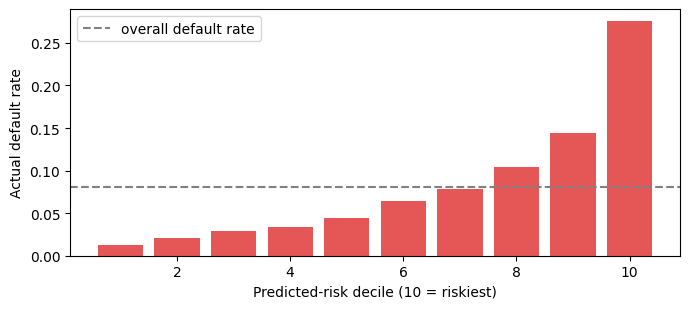

In [ ]:
val_df = pd.DataFrame({"y": y_va.values, "p": p_va})
val_df["risk_decile"] = pd.qcut(val_df["p"].rank(method="first"), 10, labels=range(1, 11)).astype(int)   # 10 = riskiest
lift = val_df.groupby("risk_decile").agg(applicants=("y", "size"), default_rate=("y", "mean"),
                                         avg_predicted=("p", "mean")).reset_index()
lift["lift_vs_average"] = lift["default_rate"] / val_df["y"].mean()
display(lift.round(4))

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.bar(lift["risk_decile"], lift["default_rate"], color="#E45756")
ax.axhline(val_df["y"].mean(), color="gray", ls="--", label="overall default rate")
ax.set_xlabel("Predicted-risk decile (10 = riskiest)"); ax.set_ylabel("Actual default rate"); ax.legend()
plt.tight_layout(); plt.show()

In [ ]:
order = np.argsort(-p_va)
y_sorted = y_va.values[order]
rows = []
for share in (0.05, 0.10, 0.20, 0.30, 0.50):
    k = int(share * len(y_sorted))
    flagged, rest = y_sorted[:k], y_sorted[k:]
    rows.append({"Riskiest share flagged": f"{share:.0%}", "Default rate, flagged": flagged.mean(),
                 "Share of all defaults caught": flagged.sum() / y_sorted.sum(), "Default rate, not flagged": rest.mean()})
display(pd.DataFrame(rows).round(3))

,Riskiest share flagged,"Default rate, flagged",Share of all defaults caught,"Default rate, not flagged"
0,5%,0.341,0.211,0.067
1,10%,0.276,0.342,0.059
2,20%,0.210,0.521,0.048
3,30%,0.175,0.650,0.040
4,50%,0.133,0.826,0.028


**Reading the deciles.** The score ranks risk well. The default rate climbs steadily from **1.2% in the safest decile to 27.6% in the riskiest**, which is 3.4 times the average (8.1%) at the top and 0.15 times at the bottom. The average predicted probability is close to the actual default rate in every decile, so the probabilities are also reasonably well calibrated, which matters for expected-loss estimates.

**What it means for the lender.**

- **Flagging the riskiest 10%** of applicants catches 34% of all defaults, and 27.6% of the flagged group defaults. These are candidates for automatic decline or manual review.
- **Flagging the riskiest 20%** catches 52% of defaults. The remaining 80% of applicants have a default rate of 4.8%, which is well under the 8.1% average.
- **The safest half** of applicants has a default rate of only 2.8%. These are candidates for automatic approval, which is where manual review hours could be saved.

The exact cutoffs should come from the cost of a default versus the profit from a good loan, plus the review capacity of the underwriting team. That is the next phase, and it is where the BPS metrics (expected credit loss, approval rate, 90+ day delinquency, manual-review volume) can be measured. Declining more applicants lowers losses but also shuts out good borrowers, so the BPS goal of approving thin-file applicants needs a thin-file analysis before thresholds are set.

## 5.4 What drives the model

To check that the score is based on sensible information, I look at the 15 features the final model uses most. Tree importance is only a rough guide: it shows what the model relies on, not what causes default, and it favors features with many distinct values. I color the high-governance fields red.

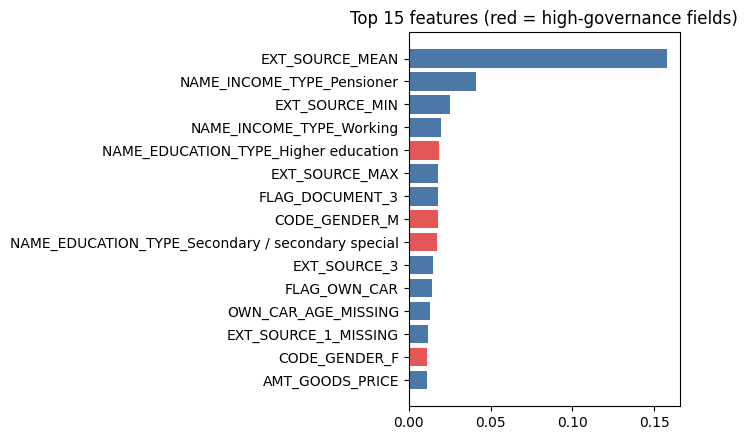

High-governance fields among the top 15: NAME_EDUCATION_TYPE_Higher education, CODE_GENDER_M, NAME_EDUCATION_TYPE_Secondary / secondary special, CODE_GENDER_F


In [ ]:
pre, model = final_pipe.named_steps["pre"], final_pipe.named_steps["model"]
feat_names = pre.get_feature_names_out()
importance = model.feature_importances_ if hasattr(model, "feature_importances_") else np.abs(model.coef_[0])
imp = (pd.DataFrame({"feature": [n.split("__", 1)[1] for n in feat_names], "importance": importance})
       .sort_values("importance", ascending=False).reset_index(drop=True))
imp["governed"] = imp["feature"].apply(lambda n: any(n.startswith(g) for g in governed))

top = imp.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(top["feature"], top["importance"], color=top["governed"].map({True: "#E45756", False: "#4C78A8"}))
ax.set_title("Top 15 features (red = high-governance fields)")
plt.tight_layout(); plt.show()
print("High-governance fields among the top 15:", ", ".join(imp.head(15).query("governed")["feature"]))

**Reading the importance chart.** The most important feature by far is **`EXT_SOURCE_MEAN`** (the average of the external scores), and the other external-score features (`EXT_SOURCE_MIN`, `EXT_SOURCE_MAX`, `EXT_SOURCE_3`, and the `EXT_SOURCE_1` missing flag) are also in the top 15. This agrees with the EDA (Q1), where the external scores were the strongest signal. Income type (pensioner and working), a document flag, car ownership, and the price of the goods are the other main non-governed features. Employment tenure is nearly absent from the top 15, probably because income type (pensioner) already captures the employment-sentinel group.

**Governance concern.** Four of the top 15 are high-governance: two education levels and both gender levels (`CODE_GENDER_M` and `CODE_GENDER_F`). Gender is explicitly something the feature report says not to use as a repayment-risk input (it is a protected characteristic under ECOA). I used all features to get the model with the best out-of-sample AUC. For the lender, section 4.2 shows the cost of removing the governed fields is small (about 0.008 AUC), so I would recommend the version without them.

# 6. Kaggle submission

The final model (trained on all training data) predicts the **probability** of default for each test application. Kaggle scores AUC, so it needs probabilities and not 0/1 labels. I align the file with `sample_submission.csv` (same IDs, same order) and check that it has one row per test application, no missing values, and probabilities between 0 and 1. As a sanity check, the average predicted probability should be close to the training default rate, which it is when no imbalance adjustment is used.

In [ ]:
submission = pd.DataFrame({"SK_ID_CURR": test_df[ID_COL].values, "TARGET": test_pred})

sample = pd.read_csv(DATA_DIR / "sample_submission.csv")
assert set(sample["SK_ID_CURR"]) == set(submission["SK_ID_CURR"])
submission = sample[["SK_ID_CURR"]].merge(submission, on="SK_ID_CURR", how="left")    # same order as the template

assert submission["SK_ID_CURR"].is_unique and submission["TARGET"].between(0, 1).all()
submission.to_csv("submission.csv", index=False)
print(f"submission.csv: {submission.shape} | mean predicted probability {submission['TARGET'].mean():.4f} "
      f"(training default rate {y_train.mean():.4f})")
display(submission.head(3))

submission.csv: (48744, 2) | mean predicted probability 0.0796 (training default rate 0.0807)


,SK_ID_CURR,TARGET
0,100001,0.045571
1,100005,0.139579
2,100013,0.026610


## Kaggle score

I submitted `submission.csv` to the Home Credit Default Risk competition. Kaggle reports a public score  and a private score.

In [ ]:
KAGGLE_PUBLIC_SCORE = 0.74454
KAGGLE_PRIVATE_SCORE = 0.74509

# 7. Results

The table collects the main numbers from the notebook, from the benchmarks to the final model.

In [ ]:
summary_rows = [
    ("Majority class", f"CV, {len(X_exp):,} rows", BASE_AUC, BASE_ACC),
    ("Logistic regression on EXT_SOURCE_MEAN", f"CV, {len(X_exp):,} rows", SIMPLE_AUC, bench_df.loc[1, "cv_accuracy"]),
    (f"Best candidate: {best_name}", f"CV, {len(X_exp):,} rows", best_row["cv_auc"], best_row["cv_accuracy"]),
    (f"Tuned {model_labels[best_key]} ({N_TUNE_ROWS:,} rows)", "CV, tuning sample", search_small.best_score_, np.nan),
    (f"Tuned {model_labels[best_key]} ({N_TUNE_ROWS_LARGE:,} rows)", "CV, tuning sample", search_large.best_score_, np.nan),
    (f"Final settings: {final_name}, train (80%)", "In-sample", TRAIN80_AUC, TRAIN80_ACC),
    (f"Final settings: {final_name}, holdout (20%)", "Out-of-sample", HOLDOUT_AUC, HOLDOUT_ACC),
]

display(pd.DataFrame(summary_rows, columns=["Model", "Evaluated on", "AUC", "Accuracy"]).round(4))

,Model,Evaluated on,AUC,Accuracy
0,Majority class,"CV, 246,008 rows",0.5000,0.9193
1,Logistic regression on EXT_SOURCE_MEAN,"CV, 246,008 rows",0.7164,0.9193
2,Best candidate: XGBoost | All features,"CV, 246,008 rows",0.7568,0.9196
3,"Tuned XGBoost (5,000 rows)","CV, tuning sample",0.7106,NaN
4,"Tuned XGBoost (25,000 rows)","CV, tuning sample",0.7420,NaN
5,"Final settings: Default settings, train (80%)",In-sample,0.7783,0.9201
6,"Final settings: Default settings, holdout (20%)",Out-of-sample,0.7596,0.9197


## Summary of findings

**1. Models and selection.** The benchmarks were AUC 0.500 (majority class) and 0.716 (one external-score variable). Of eight candidates, boosted trees ranked best: XGBoost on all features reached a cross-validated AUC of 0.7568, ahead of LightGBM (0.7552), logistic regression (0.7500), and random forest (0.7454). Logistic regression using only the EDA baseline features still reached 0.7375, so most of the signal comes from a small, explainable set of fields, mainly the external scores.

**2. Class imbalance.** None of the fixes (class weights, down-sampling, up-sampling, SMOTE) improved AUC, and all of them inflated predicted probabilities and cut accuracy at a 0.5 cutoff. I trained on the real default rate.

**3. Tuning.** Tuning on 5,000-row and 25,000-row subsamples improved the subsample cross-validation score, but the tuned settings scored *worse* on the full-data holdout (0.7495 and 0.7544) than the default settings (0.7596). Small samples favor shallow, heavily regularized trees, and these underfit with 246,000 rows. The final model therefore uses the default settings, chosen by holdout AUC. A future search would need a larger subsample or a wider range of tree depths.

**4. Final model performance.** The final XGBoost model has a holdout AUC of **0.760** (train 0.778, cross-validation 0.757). It trains in about 26 seconds and scores 48,744 applications in about 0.3 seconds. The Kaggle submission file is ready and the Kaggle score is recorded in section 6.

## How the results help solve the business problem

- **Ranking works.** On the holdout, the default rate rises from 1.2% in the safest decile to 27.6% in the riskiest. Flagging the riskiest 20% of applicants catches 52% of defaults, and the safest half of applicants has a default rate of only 2.8%. That supports the BPS routing plan: automatic approval for the lowest-risk group, automatic decline or manual review for the highest, and underwriter time spent on the middle.
- **Thresholds are the next step.** AUC only shows ranking. To measure the BPS metrics (expected credit loss, approval rate, 90+ day delinquency), I need cutoffs based on the cost of a default versus the profit from a good loan, plus a loss estimate. The predicted probabilities are close to the actual default rates by decile, so they can feed an expected-loss calculation.
- **Fairness changes the recommendation.** The best-AUC model uses gender, education, and age-related fields. Removing the governed fields costs only about 0.008 AUC (XGBoost 0.7489 without them versus 0.7568 with them). For a production score, I recommend the model without them, and a fairness check of approval rates across groups before any use.
- **Explainability.** Logistic regression on all features is only about 0.007 AUC behind XGBoost, and a logistic regression without the governed fields (0.7416) is the easiest model to turn into plain adverse-action reasons. If explainability is a priority, it is a sensible alternative to the boosted model.

## Limits and next steps

- **Application data only.** I did not use the supplementary tables (bureau, previous applications, payment history). They are the most likely route to a better score, especially for applicants with a credit history, and `Data_Prep.py` already supports them.
- **Thin-file applicants.** The BPS goal of approving more thin-file applicants has not been tested. I need a thin-file definition (for example no bureau record or missing external scores) and the AUC for that group separately. `TARGET` also exists only for applications that became loans, so declined applicants cannot be evaluated without a pilot or reject inference.
- **`TARGET` is "payment difficulty"**, while the BPS metrics refer to 90+ day delinquency and expected credit loss. These need to be matched before business results are claimed.
- **Next steps:** retrain without the governed fields, add the supplementary-table features, calibrate the probabilities, choose thresholds from costs, and check fairness across groups.